# What the label records

The challenge asks whether a recorded death is climate-sensitive. Before adding any climate variable, this notebook looks at what the records contain: where the deaths took place, what the weather columns hold, and which variables the label actually follows.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from climate_health.data import TARGET, WEATHER, load
from climate_health.plots import AQUA, BLUE, GREY, ORANGE

train, test = load()
print(f"Train: {len(train):,} deaths, {train[TARGET].mean():.1%} climate-sensitive, "
      f"{train.deathdate.min():%Y-%m-%d} to {train.deathdate.max():%Y-%m-%d}")
print(f"Test: {len(test):,} deaths, {test.deathdate.min():%Y-%m-%d} to {test.deathdate.max():%Y-%m-%d}")

Train: 3,146 deaths, 65.1% climate-sensitive, 2007-10-02 to 2022-12-13
Test: 1,030 deaths, 2007-11-24 to 2022-05-17


## 1. The test deaths come from new places

A site is one pair of coordinates. Distances are measured from the median position of the training records, which lies in the Iganga–Mayuge area of eastern Uganda.

In [2]:
centre = train[["latitude", "longitude"]].median()


def distance_km(frame):
    lat1, lon1 = np.radians(centre["latitude"]), np.radians(centre["longitude"])
    lat2, lon2 = np.radians(frame["latitude"]), np.radians(frame["longitude"])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


for name, frame in [("Train", train), ("Test", test)]:
    far = distance_km(frame) > 60
    print(f"{name}: {frame.site.nunique()} sites, {far.sum()} deaths ({far.mean():.0%}) more than 60 km away")
print(f"Sites in both: {len(set(train.site) & set(test.site))}")

sites = (pd.concat([train.assign(split="Train"), test.assign(split="Test")])
         .groupby(["split", "site", "location"])
         .agg(deaths=("ID", "size"), latitude=("latitude", "first"), longitude=("longitude", "first"))
         .reset_index())
sites["km"] = distance_km(sites)
sites[sites.km > 60].sort_values("km", ascending=False).round({"km": 0})

Train: 43 sites, 340 deaths (11%) more than 60 km away
Test: 12 sites, 307 deaths (30%) more than 60 km away
Sites in both: 0


,split,site,location,deaths,latitude,longitude,km
1,Test,"-0.590211,30.05694","Kayanga, Mitooma, Western Region, Uganda",61,-0.590211,30.056939,403.0
55,Train,"1.187892,30.782817","Kabila, Kasonga, Kikuube, Western Region, Uganda",128,1.187892,30.782817,307.0
2,Test,"0.195129,31.054964","Lubaale, Lwemiyaga, Sembabule, Uganda",130,0.195129,31.054964,274.0
0,Test,"-0.391798,32.304925","Bunyama, Kagoonya, Bujumba, Kalangala, Uganda",116,-0.391798,32.304925,171.0
12,Train,"0.089819,32.4387","Buwaya, Entebbe City, Uganda",11,0.089819,32.438700,129.0
14,Train,"0.178237,32.441904","Buwoya, Entebbe City, Uganda",2,0.178237,32.441904,125.0
13,Train,"0.145078,32.544658","Nakate Furniture, Entebbe Road, Akright City, ...",41,0.145078,32.544658,116.0
54,Train,"1.072343,34.226647","Magada, Mbale City, Bugisa sub-region, Eastern...",158,1.072343,34.226647,98.0


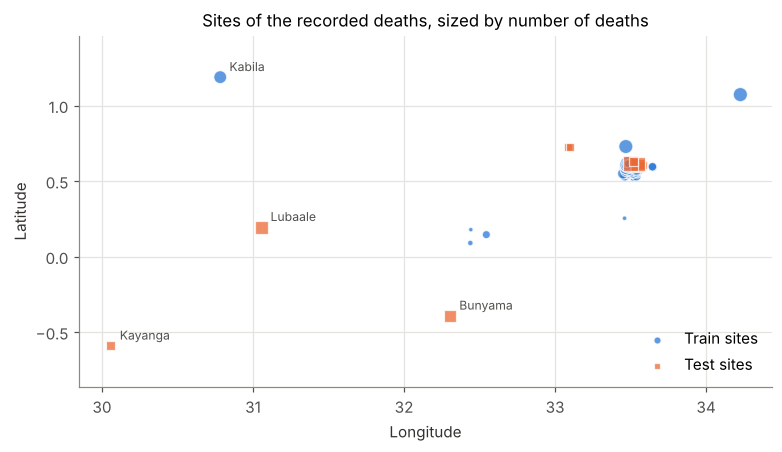

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for split, color, marker in [("Train", BLUE, "o"), ("Test", ORANGE, "s")]:
    part = sites[sites.split == split]
    ax.scatter(part.longitude, part.latitude, s=part.deaths / 2 + 8, color=color, marker=marker,
               alpha=0.75, edgecolor="white", linewidth=0.8, label=f"{split} sites")
for _, site in sites[sites.km > 150].iterrows():
    ax.annotate(site.location.split(",")[0], (site.longitude, site.latitude), xytext=(6, 4),
                textcoords="offset points", fontsize=8, color="#52514e")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal", adjustable="datalim")
ax.set_title("Sites of the recorded deaths, sized by number of deaths")
ax.legend(loc="lower right", markerscale=0.6)
fig.savefig("images/sites.png")
plt.show()

None of the 12 test sites appears in Train, so a variable that identifies a place has never been seen with a label at any test site. Most deaths sit in a small area around Iganga and Mayuge, but some are placed far outside it: 340 training deaths (11%) and 307 test deaths (30%) lie more than 60 km from its centre, up to 400 km away. The records come from a surveillance site in Iganga and Mayuge, so these coordinates most likely belong to villages of the same name elsewhere in Uganda, and any climate value looked up at them describes another place.

## 2. The weather columns are a calendar

Each record comes with an average, maximum and minimum temperature and a precipitation value. The data dictionary describes them as the weather at the location and time of the record.

In [4]:
records = pd.concat([train, test])
per_date = records.groupby("deathdate")[WEATHER].nunique().max()
print("Largest number of distinct values on a single date:", per_date.to_dict())
print(f"Dates: {records.deathdate.nunique():,}; distinct average temperatures: {records.avg_temperature.nunique():,}")

Largest number of distinct values on a single date: {'avg_temperature': 1, 'max_temperature': 1, 'min_temperature': 1, 'precipitation': 1}
Dates: 2,656; distinct average temperatures: 2,656


Every death on a given date has the same four weather values, wherever it happened: 2,656 dates and 2,656 distinct average temperatures. The columns are one regional series indexed by date, so for a model they are a code for the date of death rather than the weather where the death occurred.

## 3. The label follows age

The share of climate-sensitive deaths by age at death, for women and men.

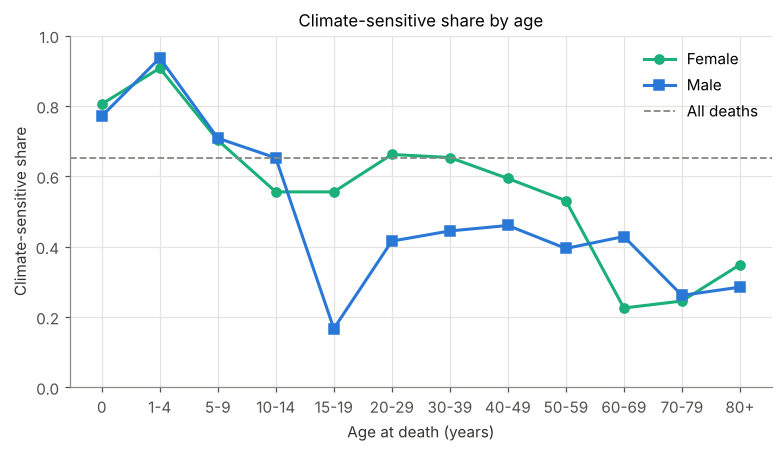

mean         size     
gender   Female  Male Female Male
age band                         
0          0.81  0.77    549  563
1-4        0.91  0.94    292  329
5-9        0.70  0.71     37   48
10-14      0.56  0.65      9   23
15-19      0.56  0.17     27   30
20-29      0.66  0.42     71   77
30-39      0.65  0.44     75   81
40-49      0.59  0.46     64  100
50-59      0.53  0.39     49   76
60-69      0.23  0.43     71   77
70-79      0.25  0.26    102  111
80+        0.35  0.28    155  130

In [5]:
bands = [0, 1, 5, 10, 15, 20, 30, 40, 50, 60, 70, 80, 120]
labels = ["0", "1-4", "5-9", "10-14", "15-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
train["age band"] = pd.cut(train.age, bands, right=False, labels=labels)
by_age = train.groupby(["age band", "gender"], observed=True)[TARGET].agg(["mean", "size"]).unstack()

fig, ax = plt.subplots(figsize=(7, 4))
for gender, color, marker in [("Female", AQUA, "o"), ("Male", BLUE, "s")]:
    ax.plot(labels, by_age[("mean", gender)], color=color, marker=marker, linewidth=2, label=gender)
ax.axhline(train[TARGET].mean(), color=GREY, linestyle="--", linewidth=1.2, label="All deaths")
ax.set_xlabel("Age at death (years)")
ax.set_ylabel("Climate-sensitive share")
ax.set_ylim(0, 1)
ax.set_title("Climate-sensitive share by age")
ax.legend()
fig.savefig("images/label_by_age.png")
plt.show()
by_age.round(2)

The climate-sensitive share is above 90% for children aged 1 to 4, falls through adolescence and is lowest after 60. Between 15 and 59, women's deaths are more often climate-sensitive than men's. The data dictionary does not say which causes of death the label covers, but its strong dependence on age means that age alone already separates most of it.

## 4. And the year of death, through infants

Among infants, the share of climate-sensitive deaths by year, next to the share of all recorded deaths that are infants. The second count uses Train and Test together, since it needs no label.

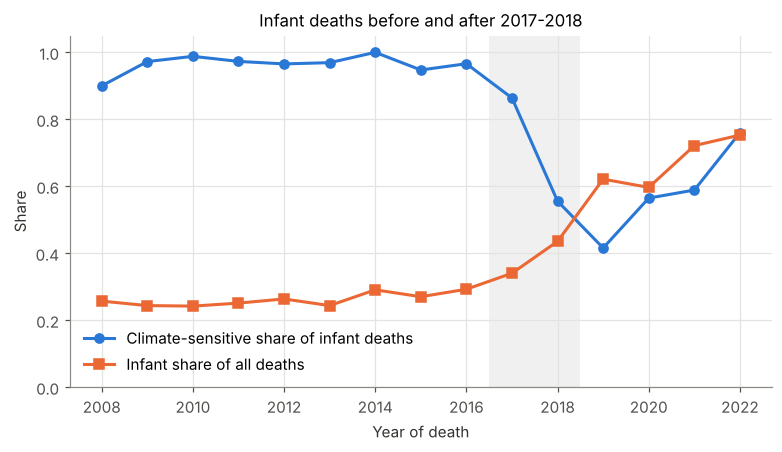

year,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
infant deaths (Train),NaN,30.00,109.00,84.00,74.00,58.00,65.00,62.00,57.00,59.00,22.00,36.00,101.00,108.00,197.00,50.00
climate-sensitive share,NaN,0.90,0.97,0.99,0.97,0.97,0.97,1.00,0.95,0.97,0.86,0.56,0.42,0.56,0.59,0.76
infant share of all deaths,0.0,0.26,0.24,0.24,0.25,0.26,0.24,0.29,0.27,0.29,0.34,0.44,0.62,0.60,0.72,0.75


In [6]:
records["infant"] = records.age == 0
infant_share = records.groupby("year")["infant"].mean()
infant_label = train[train.age == 0].groupby("year")[TARGET].agg(["mean", "size"])
years = infant_label.index[infant_label["size"] >= 10]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(years, infant_label.loc[years, "mean"], color=BLUE, marker="o", linewidth=2,
        label="Climate-sensitive share of infant deaths")
ax.plot(years, infant_share.loc[years], color=ORANGE, marker="s", linewidth=2,
        label="Infant share of all deaths")
ax.axvspan(2016.5, 2018.5, color=GREY, alpha=0.12, linewidth=0)
ax.set_xlabel("Year of death")
ax.set_ylabel("Share")
ax.set_ylim(0, 1.05)
ax.set_title("Infant deaths before and after 2017-2018")
ax.legend(loc="lower left")
fig.savefig("images/infant_shift.png")
plt.show()
pd.DataFrame({"infant deaths (Train)": infant_label["size"], "climate-sensitive share": infant_label["mean"],
              "infant share of all deaths": infant_share}).round(2).T

In [7]:
groups = pd.cut(train.age, [0, 1, 5, 15, 50, 65, 120], right=False,
                labels=["0", "1-4", "5-14", "15-49", "50-64", "65+"])
period = np.where(train.year >= 2018, "2018 on", "before 2018")
train.assign(group=groups, period=period).pivot_table(
    index=["period", "gender"], columns="group", values=TARGET, aggfunc="mean", observed=True).round(2)

group                  0   1-4  5-14  15-49  50-64   65+
period      gender                                      
2018 on     Female  0.59  0.84  0.83   0.35   0.56  0.22
            Male    0.54  0.90  0.65   0.26   0.47  0.19
before 2018 Female  0.97  0.91  0.62   0.67   0.43  0.29
            Male    0.96  0.94  0.71   0.44   0.36  0.33

Until 2016, 95% to 100% of infant deaths are climate-sensitive; within two years the share falls to 42%–59%. At the same moment the records change composition: infants go from about a quarter of all recorded deaths to 60%–75%, while fewer deaths are recorded at other ages. No other age group shows a comparable jump: children aged 1 to 4 stay mostly above 85%, and adults decline more gradually, with small samples after 2017. A shift this abrupt, concentrated in infants and coinciding with a change in who is recorded, points to a change in how deaths were recorded or classified around 2017–2018 rather than a change in climate, although the organisers have not described one. A model reads this change through the date of death.